In [ ]:
import pandas as pd
import torch
import os
use_cuda = torch.cuda.is_available() 
device = torch.device("cuda" if use_cuda else "cpu")

if use_cuda:
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

data = os.listdir('data/GestaltMatcherDB/v1.1.0/gmdb_align')
img_meta = pd.read_csv('data/GestaltMatcherDB/v1.1.0/gmdb_metadata/image_metadata_v1.1.0.tsv', sep='\t')
img_meta = img_meta[['image_id', 'filename', 'internal_syndrome_id', 'age_year','gender','ethnicity']]

training = pd.read_csv('data/GestaltMatcherDB/v1.1.0/gmdb_metadata/gmdb_train_images_v1.1.0.csv')
training = training.merge(
    img_meta[['image_id', 'age_year','gender','ethnicity']],
    on='image_id',
    how='left'   # keeps all rows in training
)
validation = pd.read_csv('data/GestaltMatcherDB/v1.1.0/gmdb_metadata/gmdb_val_images_v1.1.0.csv')
validation = validation.merge(
    img_meta[['image_id', 'age_year','gender','ethnicity']],
    on='image_id',
    how='left'   
)
test = pd.read_csv('data/GestaltMatcherDB/v1.1.0/gmdb_metadata/gmdb_test_images_v1.1.0.csv')
test = test.merge(
    img_meta[['image_id', 'age_year','gender','ethnicity']],
    on='image_id',
    how='left'   
)

####################################################
####################################################
####################################################
########## For AIDY data  ##########################
####################################################
####################################################
####################################################

# gmdb_data = pd.concat([training, validation, test], ignore_index=True)
gmdb_data = pd.concat( [test], ignore_index=True)

GM_AI_label = pd.read_csv('gmdb_aidy_label_mapping.csv')

baby_images = gmdb_data[(gmdb_data['age_year']>1) & (gmdb_data['age_year']<6)]
kid_images = gmdb_data[(gmdb_data['age_year']>5) & (gmdb_data['age_year']<10)]
adult_images = gmdb_data[(gmdb_data['age_year']>10) & (gmdb_data['age_year']<100)]
datasets = {
    "baby": baby_images,
    "kid": kid_images,
    "adult": adult_images   
}
male_images = gmdb_data[gmdb_data['gender']=='male']
female_images = gmdb_data[gmdb_data['gender']=='female']

sex_datasets = {
    "male": male_images,
    "female": female_images,
}

african_images = gmdb_data[gmdb_data['ethnicity'].str.contains('African', case=True, na=False)]
asian_images = gmdb_data[gmdb_data['ethnicity'].str.contains('Asian', case=True, na=False)]
caucasian_images = gmdb_data[gmdb_data['ethnicity'].str.contains('Caucasian', case=True, na=False)]

ethnicity_datasets = {
    "african": african_images,
    "asian": asian_images,
    "caucasian": caucasian_images,
}

k_values = [1, 5, 10, 30]

In [19]:
# Preprocessing used for ArcFace input image inference
def preprocess(img, img_size=112, gray=False, flip=False):
    img = cv2.resize(img, (img_size, img_size))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    if gray:
        # desired number of channels is 1, so we convert to gray
        img = A.to_gray(img)
    #else: color

    if flip:
        img = A.hflip(img)
    #else: normal

    # normalize pixel values in range [-1,1]
    img = np.transpose(img, (2, 0, 1))
    img = torch.from_numpy(img).unsqueeze(0).float()
    img.div_(255).sub_(0.5).div_(0.5)
    return img


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# central_model= torch.load('s1_glint360k_r100_512d_gmdb__v1.1.0_bs64_size112_channels3_last_model.pth',
#                 map_location=device).to(device)
central_model= torch.load('s2_glint360k_r100_512d_gmdb__v1.1.0_bs128_size112_channels3_last_model.pth',
                map_location=device).to(device)
swarm_model= torch.load("s1_glint360k_r100_512d_gmdb_aidy__v1.1.0_bs128_size112_channels3_swarm_model_merged.pth",
                  map_location=device).to(device)
central_model.eval().to(device)
swarm_model.eval().to(device)

def evaluate_model(data_subset, k):
    all_labels = []
    all_labels_gmdb = []
    central_topk_list = []
    swarm_topk_list = []

    with torch.no_grad():
        for idx, img_path in enumerate(tqdm(data, desc=f"Processing (k={k})")):

            img_id = int(img_path.split('_')[0])

            if len(data_subset[data_subset['image_id'] == img_id]) == 0:
                continue

            img = cv2.imread(os.path.join('data/GestaltMatcherDB/v1.1.0/gmdb_align', img_path))
            img_p = preprocess(img).to(device, dtype=torch.float32)

            # Central
            pred_c, _ = central_model(img_p)
            probs_c = torch.softmax(pred_c[:, :275], dim=1)
            topk_c = torch.topk(probs_c, k=k, dim=1).indices.cpu().numpy()

            # Swarm
            pred_s, _ = swarm_model(img_p)
            probs_s = torch.softmax(pred_s[:, :275], dim=1)
            topk_s = torch.topk(probs_s, k=k, dim=1).indices.cpu().numpy()

            central_topk_list.append(topk_c)
            swarm_topk_list.append(topk_s)

            gmdb_id = gmdb_data.loc[gmdb_data['image_id'] == img_id, gmdb_data.columns[2]].values[0]
            aidy_id = GM_AI_label.loc[GM_AI_label['GMDB_label'] == gmdb_id, GM_AI_label.columns[1]].values[0]

            all_labels.append(aidy_id)
            all_labels_gmdb.append(gmdb_id)

    labels_np = np.array(all_labels)
    labels_gmdb_np = np.array(all_labels_gmdb)
    central_topk = np.vstack(central_topk_list)
    swarm_topk = np.vstack(swarm_topk_list)

    central_acc = np.mean([labels_gmdb_np[i] in central_topk[i] for i in range(len(labels_np))])
    swarm_acc   = np.mean([labels_np[i] in swarm_topk[i] for i in range(len(labels_np))])

    return central_acc, swarm_acc

In [21]:
age_results = {}

for name, dataset in datasets.items():
    age_results[name] = {"central": [], "swarm": []}

    for k in k_values:
        c_acc, s_acc = evaluate_model(dataset, k)

        age_results[name]["central"].append(c_acc)
        age_results[name]["swarm"].append(s_acc)

sex_results = {}

for name, dataset in sex_datasets.items():
    sex_results[name] = {"central": [], "swarm": []}

    for k in k_values:
        c_acc, s_acc = evaluate_model(dataset, k)

        sex_results[name]["central"].append(c_acc)
        sex_results[name]["swarm"].append(s_acc)

ethnicity_results = {}

for name, dataset in ethnicity_datasets.items():
    ethnicity_results[name] = {"central": [], "swarm": []}

    for k in k_values:
        c_acc, s_acc = evaluate_model(dataset, k)

        ethnicity_results[name]["central"].append(c_acc)
        ethnicity_results[name]["swarm"].append(s_acc)

Processing (k=30): 100%|██████████| 10980/10980 [00:38<00:00, 282.97it/s]


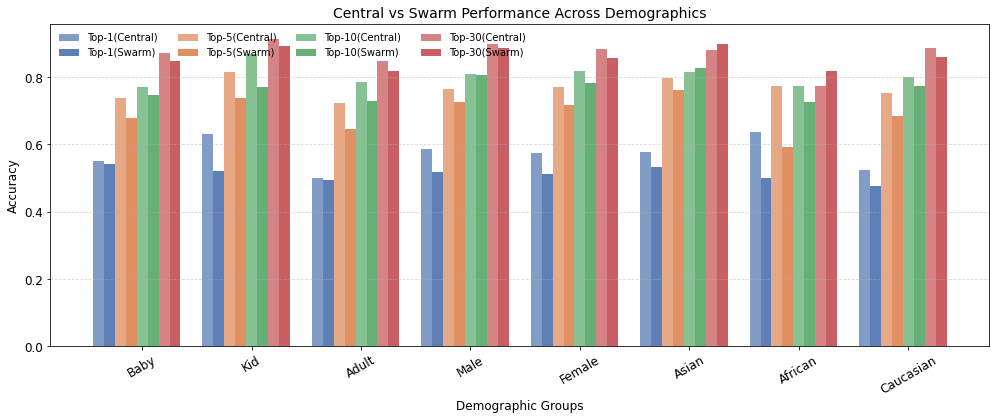

In [38]:
import numpy as np
import matplotlib.pyplot as plt

def plot_all_in_one(age_results, sex_results, ethnicity_results, k_values):
    
    # ---- Styling (publication quality) ----
    plt.rcParams.update({
        "font.size": 12,
        "axes.titlesize": 14,
        "axes.labelsize": 12,
        "legend.fontsize": 10
    })

    # ---- Combine results ----
    combined = {
        **age_results,
        **sex_results,
        **ethnicity_results
    }

    # Optional: enforce order
    groups = [
        "baby", "kid", "adult",
        "male", "female",
        "asian", "african", "caucasian"
    ]

    groups = [g for g in groups if g in combined]

    n_groups = len(groups)
    n_k = len(k_values)

    x = np.arange(n_groups)
    total_width = 0.8
    bar_width = total_width / (2 * n_k)

    fig, ax = plt.subplots(figsize=(14, 6))

    # ---- Colors ----
    colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

    # ---- Plot bars ----
    for i, k in enumerate(k_values):
        offset = (i - n_k/2) * 2 * bar_width + bar_width/2

        central_vals = [combined[g]["central"][i] for g in groups]
        swarm_vals   = [combined[g]["swarm"][i]   for g in groups]

        ax.bar(x + offset - bar_width/2, central_vals,
               bar_width, color=colors[i], alpha=0.7, label = f'Top-{k_values[i]}(Central)')

        ax.bar(x + offset + bar_width/2, swarm_vals,
               bar_width, color=colors[i], alpha=0.9,label = f'Top-{k_values[i]}(Swarm)')

    # ---- Axes ----
    ax.set_xticks(x)
    ax.set_xticklabels([g.capitalize() for g in groups], rotation=30)
    ax.set_ylabel("Accuracy")
    ax.set_xlabel("Demographic Groups")
    ax.set_title("Central vs Swarm Performance Across Demographics")

    ax.grid(axis='y', linestyle='--', alpha=0.5)

    # ---- Legend ----
    handles, labels = ax.get_legend_handles_labels()
    # ax.legend(handles, labels, loc='upper left')
    ax.legend(ncol=4, frameon=False, loc='upper left')

    # ---- Layout ----
    plt.tight_layout()

    # ---- Save high-quality ----
    plt.savefig("combined_plot.pdf", dpi=300, bbox_inches='tight')
    plt.savefig("combined_plot.png", dpi=300, bbox_inches='tight')

    plt.show()
plot_all_in_one(age_results, sex_results, ethnicity_results, k_values)

### calculating accuracy per class

In [ ]:
import torch
import pandas as pd
syndrome_name=pd.read_csv('data/GestaltMatcherDB/v1.1.0/gmdb_metadata/gmdb_syndromes_v1.1.0.tsv', sep='\t')
interesting_syndromes = ['Noonan syndrome','Coffin-Siris syndrome','CROUZON SYNDROME','Treacher Collins syndrome',
'CHROMOSOME 22q11.2 DELETION SYNDROME, DISTAL','WILLIAMS-BEUREN SYNDROME; WBS','SMITH-LEMLI-OPITZ SYNDROME; SLOS','Kabuki syndrome','ANGELMAN SYNDROME; AS','COSTELLO SYNDROME; CSTLO',
'LEOPARD syndrome','Cardiofaciocutaneous syndrome','PFEIFFER SYNDROME','APERT SYNDROME','MUENKE SYNDROME; MNKES','Cole-Carpenter syndrome','Stickler syndrome',
'SAETHRE-CHOTZEN SYNDROME; SCS','ACROFACIAL DYSOSTOSIS 1, NAGER TYPE; AFD1','CRANIOFRONTONASAL SYNDROME; CFNS', 'Orofaciodigital syndrome','CLEFT PALATE, CARDIAC DEFECTS, AND MENTAL RETARDATION; CPCMR',
'Silver-Russell syndrome','MCCUNE-ALBRIGHT SYNDROME; MAS','MARSHALL SYNDROME; MRSHS','MARSHALL-SMITH SYNDROME; MRSHSS','SMITH-LEMLI-OPITZ SYNDROME; SLOS','CHARGE SYNDROME',
'Trichorhinophalangeal syndrome','Joubert syndrome','Baraitser-Winter syndrome','Alagille syndrome','OGDEN SYNDROME; OGDNS','Robinow syndrome']
interesting_syndromes_short_name = ['Noonan','Coffin-Siris','Crouzon','Treacher-Collins',
'22q11.2','Williams-Beuren','Smith-Lemli-Opitz','Kabuki','Angelman','Costello',
'Leopard','Cardiofaciocutaneous','Pfeiffer','Apert','Muenke','Cole-Carpenter','Stickler',
'Saethre-Chotzen','Acrofacial-Nager','Cranio-Fronto-Nasal','Orofacial','Cleft Palate','Silver-Russell','Albright','Marshall','Marshall-Smith','Smith-Lemli-Opitz','Charge',
'Tricho-rhino-phalangeal','Joubert','Baraitser-Winter','Alagille','Ogden','Robinow']

# gmdb_data = pd.concat([training, validation, test], ignore_index=True)
gmdb_data = pd.concat( [validation, test], ignore_index=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# central_model= torch.load('s1_glint360k_r100_512d_gmdb__v1.1.0_bs64_size112_channels3_last_model.pth',
#                 map_location=device).to(device)
central_model= torch.load('s2_glint360k_r100_512d_gmdb__v1.1.0_bs128_size112_channels3_last_model.pth',
                map_location=device).to(device)
swarm_model= torch.load("s1_glint360k_r100_512d_gmdb_aidy__v1.1.0_bs128_size112_channels3_swarm_model_merged.pth",
                  map_location=device).to(device)
central_model.eval().to(device)
swarm_model.eval().to(device)

k_values = [1, 5, 10, 30]

all_labels = []
all_labels_gmdb = []

central_topk_dict = {k: [] for k in k_values}
swarm_topk_dict   = {k: [] for k in k_values}

with torch.no_grad():
    for idx, img_path in enumerate(tqdm(data, desc="Processing images")):

        img_id = int(img_path.split('_')[0])

        if len(gmdb_data[gmdb_data['image_id'] == img_id]) == 0:
            continue

        img = cv2.imread(os.path.join('data/GestaltMatcherDB/v1.1.0/gmdb_align', img_path))
        img_p = preprocess(img).to(device, dtype=torch.float32)

        # Central
        pred_c, _ = central_model(img_p)
        probs_c = torch.softmax(pred_c[:, :275], dim=1)

        # Swarm
        pred_s, _ = swarm_model(img_p)
        probs_s = torch.softmax(pred_s[:, :275], dim=1)

      
        for k in k_values:
            central_topk_dict[k].append(
                torch.topk(probs_c, k=k, dim=1).indices.cpu().numpy()
            )
            swarm_topk_dict[k].append(
                torch.topk(probs_s, k=k, dim=1).indices.cpu().numpy()
            )

        gmdb_id = gmdb_data.loc[gmdb_data['image_id'] == img_id, gmdb_data.columns[2]].values[0]
        aidy_id = GM_AI_label.loc[GM_AI_label['GMDB_label'] == gmdb_id, GM_AI_label.columns[1]].values[0]

        all_labels.append(aidy_id)
        all_labels_gmdb.append(gmdb_id)

labels_np = np.array(all_labels)
labels_gmdb_np = np.array(all_labels_gmdb)

central_topk_dict = {k: np.vstack(v) for k, v in central_topk_dict.items()}
swarm_topk_dict   = {k: np.vstack(v) for k, v in swarm_topk_dict.items()}

unique_labels = np.unique(labels_np)

results = {}

for lbl in unique_labels:
    mask = labels_np == lbl

    lbl_gmdb = GM_AI_label.loc[
        GM_AI_label['AIDY_GMDB_label'] == lbl,
        GM_AI_label.columns[0]
    ].values[0]

    mask_gmdb = labels_gmdb_np == lbl_gmdb
    idxs = np.where(mask)[0]
    idxs_gmdb = np.where(mask_gmdb)[0]

    if len(idxs) == 0:
        continue

    results[lbl] = {
        "central": [],
        "swarm": []
    }

    for k in k_values:
        central_acc = np.mean([
            labels_gmdb_np[i] in central_topk_dict[k][i]
            for i in idxs_gmdb
        ])

        swarm_acc = np.mean([
            labels_np[i] in swarm_topk_dict[k][i]
            for i in idxs
        ])

        results[lbl]["central"].append(central_acc)
        results[lbl]["swarm"].append(swarm_acc)

df_list = []

for lbl, val in results.items():
    df_list.append({
        "Label AIDY": lbl,
        "Central": val["central"],
        "Swarm": val["swarm"]
    })

df_acc = pd.DataFrame(df_list)
df_acc = df_acc.merge(
    GM_AI_label[['AIDY_GMDB_label', 'GMDB_label']],
    left_on='Label AIDY',
    right_on='AIDY_GMDB_label',
    how='left'
)

df_acc = df_acc.merge(
    syndrome_name[['syndrome_id','syndrome_name']],
    left_on='GMDB_label',
    right_on='syndrome_id',
    how='left'
)
import re

pattern = '|'.join([re.escape(s.lower()) for s in interesting_syndromes])

interesting = df_acc[
    df_acc['syndrome_name'].str.lower().str.contains(pattern, na=False)
]
def get_short_name(full_name):
    full_lower = full_name.lower()
    for long, short in zip(interesting_syndromes, interesting_syndromes_short_name):
        if long.lower() in full_lower:
            return short
    return full_name  # fallback

interesting['short_name'] = interesting['syndrome_name'].apply(get_short_name)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']
topk=2
def plot_topk10_only(interesting):
   
    n_diseases = len(interesting)
    bar_width = 0.35
    x = np.arange(n_diseases)
    
    central_vals = [row["Central"][topk] for _, row in interesting.iterrows()]  # k=10 is index 2
    swarm_vals   = [row["Swarm"][topk]   for _, row in interesting.iterrows()]

    plt.figure(figsize=(14,6))
    plt.bar(x - bar_width/2, central_vals, width=bar_width, color=colors[0], alpha=1, label='Central')
    plt.bar(x + bar_width/2, swarm_vals,   width=bar_width, color=colors[1], alpha=1, label='Swarm')

    short_names =  interesting['short_name']
    plt.xticks(x, short_names, rotation=45, ha='right')
    plt.ylabel("Accuracy")
    plt.xlabel("Syndromes")
    plt.title("Top 30 Syndromes: Central vs Swarm Accuracy at Top-K=10")
    plt.grid(axis='y', linestyle='--', alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()
plot_topk10_only(interesting)

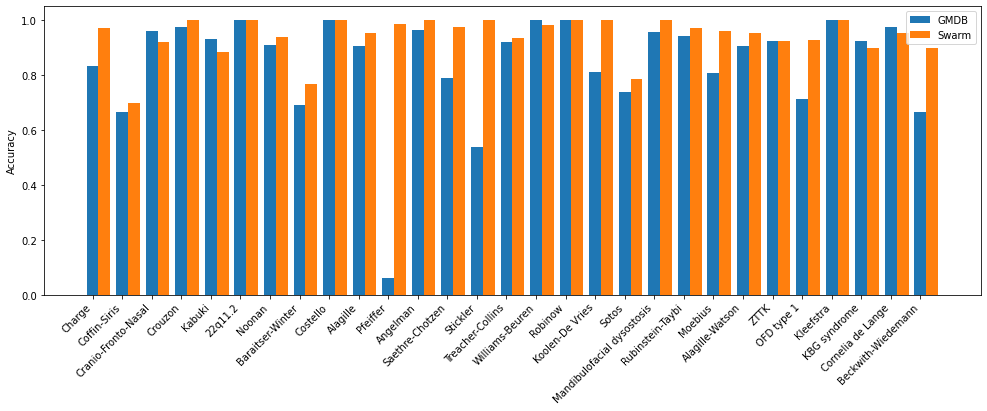

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Data
data = [
    ["Charge", 0.8333, 0.9722],
    ["Coffin-Siris", 0.6667, 0.7],
    ["Cranio-Fronto-Nasal", 0.96, 0.92],
    ["Crouzon", 0.9762, 1],
    ["Kabuki", 0.931, 0.8851],
    ["22q11.2", 1, 1],
    ["Noonan", 0.9077, 0.9385],
    ["Baraitser-Winter", 0.6923, 0.7692],
    ["Costello", 1, 1],
    ["Alagille", 0.9048, 0.9524],
    ["Pfeiffer", 0.0625, 0.9844],
    ["Angelman", 0.963, 1],
    ["Saethre-Chotzen", 0.7907, 0.9767],
    ["Stickler", 0.5385, 1],
    ["Treacher-Collins", 0.9194, 0.9355],
    ["Williams-Beuren", 1, 0.9828],
    ["Robinow", 1, 1],
    ["Koolen-De Vries", 0.8125, 1],
    ["Sotos", 0.7381, 0.7857],
    ["Mandibulofacial dysostosis", 0.9574, 1],
    ["Rubinstein-Taybi", 0.9412, 0.9706],
    ["Moebius", 0.8077, 0.9615],
    ["Alagille-Watson", 0.9048, 0.9524],
    ["ZTTK", 0.9231, 0.9231],
    ["OFD type 1", 0.7143, 0.9286],
    ["Kleefstra", 1, 1],
    ["KBG syndrome", 0.9231, 0.8974],
    ["Cornelia de Lange", 0.9767, 0.9535],
    ["Beckwith-Wiedemann", 0.6667, 0.8974],
]
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']
# Create DataFrame
df = pd.DataFrame(data, columns=["Disease", "GMDB Top 10", "Swarm Top 10"])

# Plot
plt.figure(figsize=(14, 6))
x = range(len(df))

plt.bar(x, df["GMDB Top 10"], width=0.4, label="GMDB", align='center')
plt.bar([i + 0.4 for i in x], df["Swarm Top 10"], width=0.4, label="Swarm")

# Labels and formatting
plt.xticks([i for i in x], df["Disease"], rotation=45,ha='right')
plt.ylabel("Accuracy")
#plt.title("GMDB vs Swarm Model (Top 10)")
plt.legend()
plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "legend.fontsize": 12
})
plt.tight_layout()


# Show plot
plt.show()

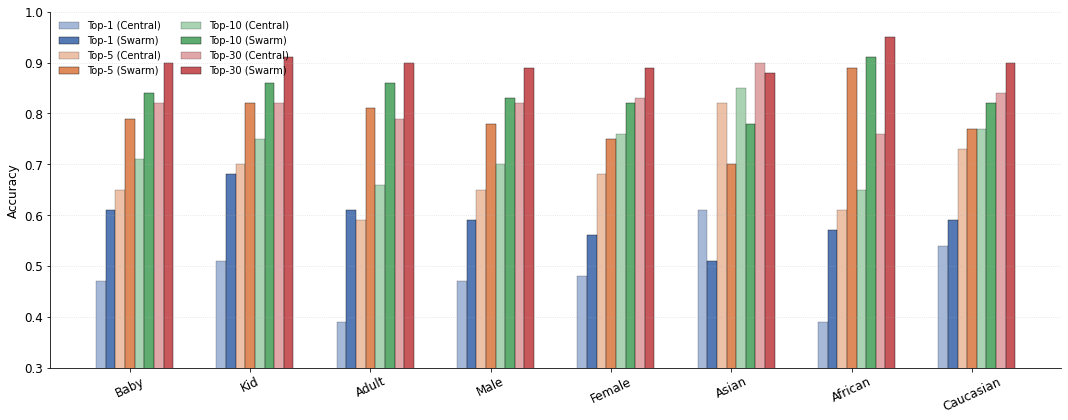

In [23]:
import numpy as np
import matplotlib.pyplot as plt

groups = ['Baby','Kid','Adult','Male','Female','Asian','African','Caucasian']
topk_labels = ['Top-1','Top-5','Top-10','Top-30']

central = np.array([
    [0.47,0.65,0.71,0.82],
    [0.51,0.70,0.75,0.82],
    [0.39,0.59,0.66,0.79],
    [0.47,0.65,0.70,0.82],
    [0.48,0.68,0.76,0.83],
    [0.61,0.82,0.85,0.90],
    [0.39,0.61,0.65,0.76],
    [0.54,0.73,0.77,0.84]
])

swarm = np.array([
    [0.61,0.79,0.84,0.90],
    [0.68,0.82,0.86,0.91],
    [0.61,0.81,0.86,0.90],
    [0.59,0.78,0.83,0.89],
    [0.56,0.75,0.82,0.89],
    [0.51,0.70,0.78,0.88],
    [0.57,0.89,0.91,0.95],
    [0.59,0.77,0.82,0.90]
])

# Muted, publication-friendly palette
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']
# colors = ['#0072B2',  # blue
#           '#E69F00',  # orange
#           '#009E73',  # green
#           '#D55E00']  # vermillion


x = np.arange(len(groups))
width = 0.08

fig, ax = plt.subplots(figsize=(15,6))

for i in range(4):
    # Central = lighter
    ax.bar(x + (i-1.5)*2*width,
           central[:, i],
           width,
           color=colors[i],
           alpha=0.5,
           edgecolor='black',
           linewidth=0.4,
           label=f'{topk_labels[i]} (Central)')
    
    # Swarm = darker
    ax.bar(x + (i-1.5)*2*width + width,
           swarm[:, i],
           width,
           color=colors[i],
           alpha=0.95,
           edgecolor='black',
           linewidth=0.4,
           label=f'{topk_labels[i]} (Swarm)')

# Formatting
ax.set_xticks(x)
ax.set_xticklabels(groups, rotation=25)
ax.set_ylabel('Accuracy')
ax.set_ylim(0.3, 1.0)

#ax.set_title('Central vs Swarm Across Demographics', pad=12)

# Subtle grid
ax.grid(axis='y', linestyle=':', alpha=0.4)

# Legend (2 rows, compact)
ax.legend(ncol=2, frameon=False, loc='upper left')

# Clean spines
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()